<a href="https://colab.research.google.com/github/DiegoMartell/Machine-Learning/blob/main/hands-on/hands_on_3_Polynomial_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📈 Regresión Polinomial en Machine Learning
### Ajuste de Curvas con Scikit-Learn

> **Objetivo del Tutorial**
> Este notebook es una guía paso a paso para implementar la técnica de **Regresión Polinomial** utilizando Python y Scikit-Learn.
> A diferencia de la regresión lineal que traza una línea recta, la regresión polinomial nos permite modelar relaciones **no lineales** ajustando una curva de grado $n$ a los datos.

## 1. Fundamentos Teóricos del Least Squared Regressor

El método de **Mínimos Cuadrados Ordinarios (Ordinary Least Squares - OLS)** es la base matemática sobre la cual Scikit-Learn optimiza el ajuste de curvas.

* **El problema:** Tenemos una serie de puntos en un plano cartesiano (datos reales) y queremos encontrar la línea o curva matemática que pase lo más cerca posible de todos ellos al mismo tiempo.
* **El error (Residuo):** Es la distancia vertical entre el punto de dato real y la curva teórica.
* **El principio de Mínimos Cuadrados:** Establece que la mejor curva es aquella que **minimiza la suma de los errores al cuadrado**.

¿Por qué al cuadrado?
1. Para que los errores positivos (puntos por encima de la curva) y negativos (por debajo) no se cancelen entre sí.
2. Para castigar exponencialmente a las predicciones que están muy lejos del valor real.

## 2. Modelo Matemático y Analítico

### Regresión Lineal vs Polinomial
Una regresión lineal simple tiene la forma clásica de una línea recta:
$$y = \beta_0 + \beta_1 x$$

Sin embargo, si nuestros datos tienen curvatura (por ejemplo, el crecimiento poblacional, desgaste térmico, etc.), una línea recta fracasará. Aquí entra la **Regresión Polinomial de grado $n$**:
$$y = \beta_0 + \beta_1 x + \beta_2 x^2 + \beta_3 x^3 + \dots + \beta_n x^n$$

* **Donde:**
  * $y$: Es la variable dependiente (lo que queremos predecir).
  * $x$: Es la variable independiente.
  * $\beta_0, \beta_1 \dots \beta_n$: Son los coeficientes que el modelo de *Machine Learning* va a descubrir para dar forma a la curva.

> **El truco de Machine Learning:**
> Matemáticamente, la regresión polinomial **sigue siendo una regresión lineal**. Lo que hacemos es un truco de preprocesamiento: tomamos nuestra única variable de entrada $x$, y creamos nuevas variables sintéticas elevándola al cuadrado ($x^2$), al cubo ($x^3$), etc. Luego, introducimos todas esas variables en un modelo lineal estándar.

In [ ]:
# Importamos las librerías base necesarias para cálculos y gráficos
import numpy as np          # Para cálculos numéricos y generación de datos
import pandas as pd         # Para manejo de DataFrames
import matplotlib.pyplot as plt # Para graficar los resultados
import seaborn as sns       # Para estilos gráficos avanzados

print(" Librerías base cargadas.")

 Librerías base cargadas.


## 3. Pipeline de Machine Learning

### 3.1 Recolección y Generación de Datos
En este tutorial, en lugar de usar un dataset preexistente que podría no tener la curvatura ideal para la enseñanza, vamos a generar un dataset sintético que represente un fenómeno físico altamente no-lineal (como la aceleración o fatiga de un material).

### 3.2 Descripción y Scatter Plot
Generaremos datos con una relación cúbica oculta ($x^3$) y le inyectaremos ruido estadístico para simular el mundo real.

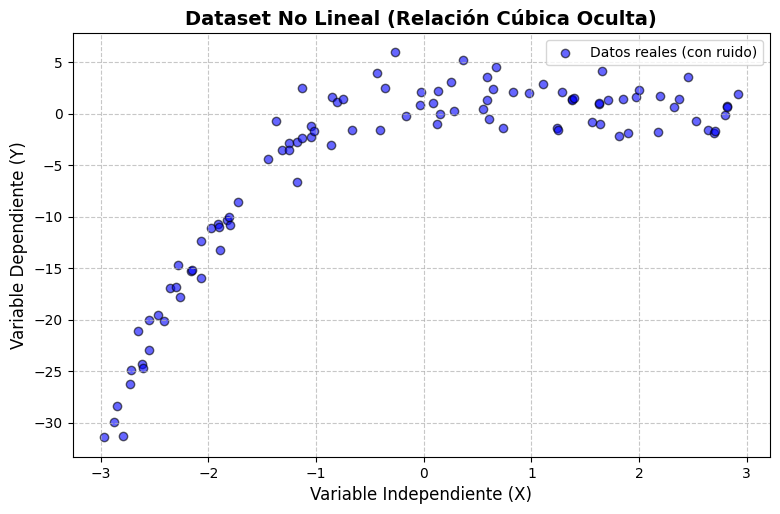

Como se observa, es imposible trazar una línea recta que explique el comportamiento de estos puntos.


In [ ]:
# Fijamos la semilla aleatoria para que el experimento sea reproducible
np.random.seed(42)

# 1. Generamos 100 muestras aleatorias para la variable independiente X (entre -3 y 3)
# reshape(-1, 1) convierte el array en una columna, formato requerido por Scikit-Learn
X = np.sort(6 * np.random.rand(100, 1) - 3, axis=0)

# 2. Creamos la variable objetivo y (dependiente) usando un polinomio de grado 3
# Fórmula base: y = 0.5 * x^3 - 2 * x^2 + x + 2 + Ruido Gausiano
y = 0.5 * X**3 - 2 * X**2 + X + 2 + np.random.randn(100, 1) * 2

# 3. Visualizamos nuestros datos crudos mediante un Scatter Plot
plt.figure(figsize=(9, 5.5))
plt.scatter(X, y, color='blue', alpha=0.6, edgecolors='k', label="Datos reales (con ruido)")
plt.title('Dataset No Lineal (Relación Cúbica Oculta)', fontsize=14, fontweight='bold')
plt.xlabel('Variable Independiente (X)', fontsize=12)
plt.ylabel('Variable Dependiente (Y)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()

print("Como se observa, es imposible trazar una línea recta que explique el comportamiento de estos puntos.")

### 3.3 Preprocesamiento: Transformación Polinomial

Antes de entrenar un modelo, debemos transformar matemáticamente nuestras entradas. Utilizaremos la clase `PolynomialFeatures` de Scikit-Learn.

Para cumplir con el requerimiento del tutorial (Polinomio de grado $n > 3$), usaremos **grado 4**.

Si nuestra entrada original es $[x]$, la transformación generará un vector con las potencias:
$[1, x, x^2, x^3, x^4]$

In [ ]:
# Importamos las herramientas de Scikit-Learn
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# 1. Separamos los datos en conjunto de Entrenamiento (80%) y Prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Instanciamos el transformador polinomial con grado 4 (n > 3)
grado_polinomio = 4
poly_features = PolynomialFeatures(degree=grado_polinomio, include_bias=False)

# 3. Ajustamos y transformamos únicamente las características de entrenamiento
# Esto añade las columnas de X al cuadrado, al cubo y a la cuarta potencia
X_train_poly = poly_features.fit_transform(X_train)

# Transformamos los datos de prueba usando el mismo molde
X_test_poly = poly_features.transform(X_test)

print(f"Forma original de X_train: {X_train.shape}")
print(f"Forma después de la transformación polinomial (grado {grado_polinomio}): {X_train_poly.shape}")
print("Las 4 columnas ahora representan: [x, x^2, x^3, x^4]")

Forma original de X_train: (80, 1)
Forma después de la transformación polinomial (grado 4): (80, 4)
Las 4 columnas ahora representan: [x, x^2, x^3, x^4]


### 3.4 Selección y Entrenamiento del Modelo

Ahora que nuestras características tienen múltiples dimensiones polinómicas, podemos utilizar un Regresor Lineal Ordinario clásico (`LinearRegression`). Este algoritmo aplicará el principio de *Mínimos Cuadrados* para encontrar los pesos óptimos de cada exponente.

In [ ]:
# Instanciamos el modelo de Regresión Lineal de Scikit-Learn
lin_reg = LinearRegression()

# Entrenamos el modelo pasándole los datos de entrada transformados y los valores reales y_train
lin_reg.fit(X_train_poly, y_train)

print("Entrenamiento completado.")
print("\nEcuación polinomial descubierta por el modelo:")
print(f"y = {lin_reg.intercept_[0]:.2f} + ({lin_reg.coef_[0][0]:.2f})*x + ({lin_reg.coef_[0][1]:.2f})*x^2 + ({lin_reg.coef_[0][2]:.2f})*x^3 + ({lin_reg.coef_[0][3]:.2f})*x^4")

Entrenamiento completado.

Ecuación polinomial descubierta por el modelo:
y = 1.98 + (0.99)*x + (-2.02)*x^2 + (0.52)*x^3 + (0.00)*x^4


### 3.5 Evaluación del Modelo (Métricas y Gráfica)

Para evaluar matemáticamente qué tan bien se ajusta la curva a la realidad, utilizamos dos métricas clave de la regresión:

1. **Mean Squared Error (MSE):** Mide el promedio de los errores al cuadrado (las distancias entre la predicción y el valor real). Entre más cerca de 0, mejor.
2. **Coeficiente de Determinación ($R^2$):** Indica qué porcentaje de la variabilidad de los datos es explicado por la curva. Su máximo perfecto es $1.0$ (o 100%).

--- RESULTADOS DE EVALUACIÓN (CONJUNTO DE PRUEBA) ---
Error Cuadrático Medio (MSE): 2.7677
Coeficiente R^2: 0.9739 (El modelo explica el 97.39% de la varianza)


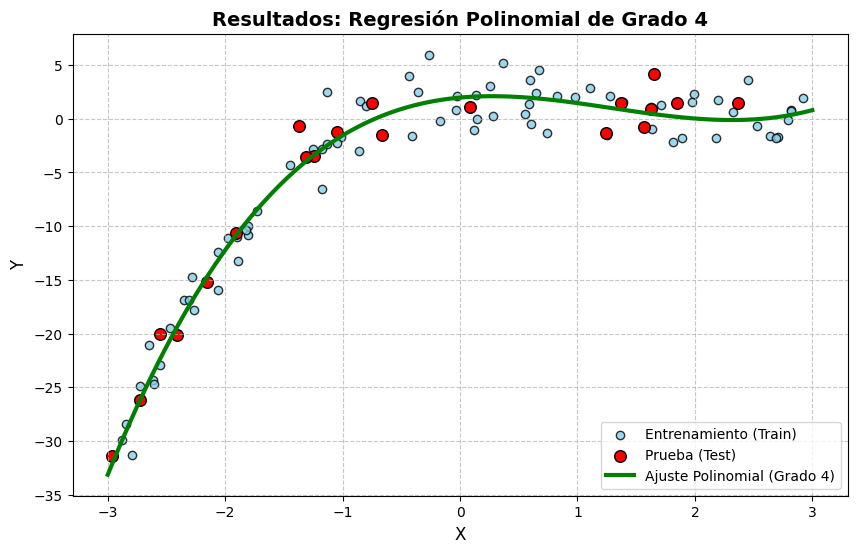

In [ ]:
# Importamos las métricas de evaluación
from sklearn.metrics import mean_squared_error, r2_score

# Generamos las predicciones del modelo sobre el conjunto de prueba (datos no vistos)
y_pred = lin_reg.predict(X_test_poly)

# Calculamos las métricas comparando las predicciones contra los valores reales
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("--- RESULTADOS DE EVALUACIÓN (CONJUNTO DE PRUEBA) ---")
print(f"Error Cuadrático Medio (MSE): {mse:.4f}")
print(f"Coeficiente R^2: {r2:.4f} (El modelo explica el {r2*100:.2f}% de la varianza)")


# VISUALIZACIÓN FINAL DE LA CURVA DE AJUSTE


# Generamos un vector de muchos puntos consecutivos para dibujar una curva suave
X_new = np.linspace(-3, 3, 100).reshape(100, 1)

# Transformamos estos nuevos puntos a polinomio grado 4
X_new_poly = poly_features.transform(X_new)

# Hacemos que el modelo dibuje la curva basándose en los puntos generados
y_new = lin_reg.predict(X_new_poly)

plt.figure(figsize=(10, 6))
# 1. Dibujamos los datos de entrenamiento originales (en azul claro)
plt.scatter(X_train, y_train, color="skyblue", edgecolor='k', label="Entrenamiento (Train)", alpha=0.8)
# 2. Dibujamos los datos de prueba (en rojo para ver si cayeron cerca de la curva)
plt.scatter(X_test, y_test, color="red", edgecolor='k', label="Prueba (Test)", s=70)
# 3. Dibujamos la curva polinomial ajustada por el modelo (en verde)
plt.plot(X_new, y_new, "g-", linewidth=3, label=f"Ajuste Polinomial (Grado {grado_polinomio})")

plt.title(f'Resultados: Regresión Polinomial de Grado {grado_polinomio}', fontsize=14, fontweight='bold')
plt.xlabel('X', fontsize=12)
plt.ylabel('Y', fontsize=12)
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()